# Real Bridge Column-Only Segmentation Evaluation & Visualization

This notebook evaluates segmentation models exclusively on the **Column region** of each bridge photograph using the Labelbox NDJSON export.

### Column-Restricted Evaluation Methodology (Patched Inference):
1. **Ground Truth Filtering**: Labelbox `cracks` and `column` polygons are rasterized at full resolution into binary masks. Ground truth is strictly restricted to cracks on the column (`gt_mask = crack_mask & column_mask`).
2. **Native Resolution Patched Inference**: High-resolution images are evaluated using sliding-window patch inference (`predict_with_patches`, 448x448, stride 224, AMP) for PyTorch models and full-resolution YOLO segmentation, preserving thin crack details.
3. **Column Domain Masking**: All model predictions are masked strictly by the column ROI (`pred_mask = pred_mask & column_mask`). Surrounding background, sky, beams, and abutments are excluded.
4. **Area Metrics (Column Domain)**: IoU, Dice, Precision, and Recall are evaluated over the column-masked predictions. Pixel Accuracy and Specificity are evaluated strictly across column pixels.
5. **Topology & Centerline Metrics**: Medial-axis centerlines, clDice, and distance-tolerant buffer metrics ($\tau = 20\text{ px}$) are extracted strictly from column cracks.
6. **Visualizations**: Section 5 generates 5-panel visual comparisons showing the original bridge image, ground truth column crack mask (with cyan column boundary), and UNet, SegFormer (Dice+Focal), and YOLO-seg overlays exclusively on the column.


In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import csv
import json
from pathlib import Path

import numpy as np
import torch
from PIL import Image, ImageDraw
from tqdm.auto import tqdm

from crack_seg import config
from crack_seg.predict import predict_with_patches
from crack_seg.utils.helpers import (
    load_model,
    create_red_overlay,
    predict_yolo_mask,
    warmup_gpu,
    predict_mask,
)
from crack_seg.utils.visualization import (
    plot_overlay_comparison,
    visualize_model_overlays,
)
from crack_seg.utils.metrics import (
    centerline_buffer_metrics,
    cldice_score,
    crack_orientation_mae,
    dice_coefficient,
    iou_score,
    pixel_accuracy,
    precision_score,
    recall_score,
    specificity_score,
)

BRIDGE_DIR = config.DATA_ROOT / "real_bridge_sample"
ANNOTATION_FILE = BRIDGE_DIR / "Export  project - Bridge_cracks - 10_26_2026.ndjson"
RESULTS_CSV = config.BASE_DIR / "experimenting" / "real_bridge_eval_v2_metrics.csv"

SKELETON_METHOD = getattr(config, "SKELETON_METHOD", "lee")
TOLERANCE_PX = float(getattr(config, "CENTERLINE_TOLERANCE_PX", 20.0))
TOL_TAG = int(TOLERANCE_PX) if TOLERANCE_PX.is_integer() else f"{TOLERANCE_PX:.1f}"
OPEN_KERNEL_SIZE = 10
CLOSE_KERNEL_SIZE = 10
CLOSE_DILATE_ITERS = 5
CLOSE_ERODE_ITERS = 1

# Batched sliding-window patch inference configuration
PATCH_SIZE = 448
STRIDE = 224
PATCH_BATCH_SIZE = 16
USE_AMP = True
YOLO_CONFIDENCE = 0.15

if not BRIDGE_DIR.is_dir():
    raise FileNotFoundError(f"Bridge data directory not found: {BRIDGE_DIR}")
if not ANNOTATION_FILE.is_file():
    raise FileNotFoundError(f"Labelbox export not found: {ANNOTATION_FILE}")

print(f"Device: {config.DEVICE}")
print(f"Patch size / stride: {PATCH_SIZE} / {STRIDE}")
print(f"Patch batch size: {PATCH_BATCH_SIZE}, AMP: {USE_AMP}")
print(f"Centerline tolerance: {TOLERANCE_PX}px")
print(f"Annotation file: {ANNOTATION_FILE.name}")


c:\Users\abinashm\AppData\Local\anaconda3\envs\computerVision\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Patch size / stride: 448 / 224
Patch batch size: 16, AMP: True
Centerline tolerance: 20.0px
Annotation file: Export  project - Bridge_cracks - 10_26_2026.ndjson


In [2]:
# Match each Labelbox external_id to the local image and rasterize full-resolution crack and column polygons.
records = [
    json.loads(line)
    for line in ANNOTATION_FILE.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
local_images = {
    path.name.casefold(): path
    for path in BRIDGE_DIR.iterdir()
    if path.is_file() and path.suffix.casefold() in (".jpg", ".jpeg", ".png")
}
record_names = [record["data_row"]["external_id"] for record in records]
record_keys = [name.casefold() for name in record_names]

if len(record_keys) != len(set(record_keys)):
    raise ValueError("The Labelbox export contains duplicate image external_id values.")
missing_images = sorted(set(record_keys) - set(local_images))
unannotated_images = sorted(set(local_images) - set(record_keys))
if missing_images or unannotated_images:
    raise ValueError(
        "Local JPGs and Labelbox rows do not match. "
        f"Missing local files: {missing_images}; without labels: {unannotated_images}"
    )

bridge_samples = []
for record in records:
    image_name = record["data_row"]["external_id"]
    image_path = local_images[image_name.casefold()]
    image = Image.open(image_path).convert("RGB")
    width, height = image.size
    attributes = record.get("media_attributes", {})
    expected_size = (attributes.get("width"), attributes.get("height"))
    if expected_size != image.size:
        raise ValueError(
            f"Image size mismatch for {image_name}: local {image.size}, Labelbox {expected_size}"
        )

    # Separate cracks and column annotations
    crack_objects = []
    column_objects = []
    for project in (record.get("projects") or {}).values():
        for label in project.get("labels", []):
            for obj in label.get("annotations", {}).get("objects", []):
                val = str(obj.get("value", "")).casefold()
                name = str(obj.get("name", "")).casefold()
                if "crack" in val or "crack" in name:
                    crack_objects.append(obj)
                elif "column" in val or "column" in name:
                    column_objects.append(obj)

    if not column_objects:
        raise ValueError(f"No column annotation found for {image_name}.")
    if not crack_objects:
        raise ValueError(f"No crack annotations found for {image_name}.")

    # 1. Rasterize full-resolution crack mask
    crack_mask = Image.new("L", image.size, 0)
    crack_draw = ImageDraw.Draw(crack_mask)
    for obj in crack_objects:
        polygon = obj.get("polygon") or []
        if len(polygon) < 3:
            raise ValueError(f"Invalid crack polygon in {image_name}.")
        points = [(round(float(p["x"])), round(float(p["y"]))) for p in polygon]
        crack_draw.polygon(points, fill=255)

    # 2. Rasterize full-resolution column mask
    col_mask = Image.new("L", image.size, 0)
    col_draw = ImageDraw.Draw(col_mask)
    for obj in column_objects:
        polygon = obj.get("polygon") or []
        if len(polygon) < 3:
            raise ValueError(f"Invalid column polygon in {image_name}.")
        points = [(round(float(p["x"])), round(float(p["y"]))) for p in polygon]
        col_draw.polygon(points, fill=255)

    # 3. Intersect cracks with column (ignore any crack outside column)
    crack_arr = np.array(crack_mask) > 128
    col_arr = np.array(col_mask) > 128
    gt_column_crack_arr = (crack_arr & col_arr).astype(np.uint8) * 255

    gt_pixels = int((gt_column_crack_arr > 128).sum())
    if gt_pixels == 0:
        raise ValueError(f"Column crack mask is empty for {image_name}.")

    bridge_samples.append((
        image_name,
        image_path,
        col_arr,
        gt_column_crack_arr,
        column_objects,
    ))
    col_pct = col_arr.mean() * 100
    print(
        f"{image_name} ({width}x{height}): {len(crack_objects)} crack polygons, "
        f"{len(column_objects)} column polygon(s) ({col_pct:.1f}% area), "
        f"GT column crack pixels={gt_pixels}"
    )

print(f"\nLoaded {len(bridge_samples)} annotated bridge images (column-restricted).")


2401-Mar-11-2021 (46).jpg (3024x4032): 19 crack polygons, 1 column polygon(s) (60.9% area), GT column crack pixels=156857
2401-Mar-11-2021 (47).jpg (3024x4032): 11 crack polygons, 1 column polygon(s) (46.5% area), GT column crack pixels=97046
2401-Mar-11-2021 (59).JPG (1242x2439): 19 crack polygons, 1 column polygon(s) (64.1% area), GT column crack pixels=36118
learningfromearthquakes.org-2011_03_11_tohoku_japan-P1040486.jpg (4000x3000): 9 crack polygons, 1 column polygon(s) (77.2% area), GT column crack pixels=58815
learningfromearthquakes.org-2011-03-11-tohoku-japan-P1040451.jpg (4000x3000): 2 crack polygons, 1 column polygon(s) (59.2% area), GT column crack pixels=30693

Loaded 5 annotated bridge images (column-restricted).


In [3]:
# Keep the same checkpoint set as eval_exp2.ipynb; unavailable checkpoints are skipped.
MODELS_TO_EVALUATE = {
    "UNet (NCCD-PF)": {
        "type": "unet",
        "path": config.CHECKPOINT_DIR / "unet_NCCD-PF_Dataset.pth",
    },
    "UNet (4 Datasets)": {
        "type": "unet",
        "path": config.CHECKPOINT_DIR / "unet_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth",
    },
    "SegFormer (4 Datasets)": {
        "type": "segformer",
        "path": config.CHECKPOINT_DIR / "segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth",
    },
    "SegFormer (Focal)": {
        "type": "segformer",
        "path": config.CHECKPOINT_DIR / "segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500_focal.pth",
    },
    "SegFormer (Dice+Focal)": {
        "type": "segformer",
        "path": config.CHECKPOINT_DIR / "segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500_dice_focal.pth",
    },
    "YOLO-seg (4 Datasets)": {
        "type": "yolo",
        "path": config.CHECKPOINT_DIR
        / "yolo_runs"
        / "yolo_seg_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pt",
    },
}

active_models = {
    name: info
    for name, info in MODELS_TO_EVALUATE.items()
    if Path(info["path"]).is_file()
}
for name, info in MODELS_TO_EVALUATE.items():
    status = "found" if name in active_models else "missing; skipped"
    print(f"{status:16} {name}: {info['path']}")
if not active_models:
    raise FileNotFoundError(f"No evaluation checkpoints found in {config.CHECKPOINT_DIR}.")

loaded_models = {}
for name, info in active_models.items():
    loaded_models[name] = (
        info["type"],
        load_model(info["type"], info["path"], device=config.DEVICE),
    )
print(f"\nLoaded {len(loaded_models)} model(s).")


found            UNet (NCCD-PF): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\checkpoints\unet_NCCD-PF_Dataset.pth
found            UNet (4 Datasets): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\checkpoints\unet_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth
found            SegFormer (4 Datasets): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\checkpoints\segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth
found            SegFormer (Focal): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\checkpoints\segformer_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500_focal.pth
found            SegFormer (Dice+Focal): C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentati

In [4]:
metric_names = [
    "IoU",
    "Dice",
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "clDice",
    f"Centerline_Prec@{TOL_TAG}",
    f"Centerline_Rec@{TOL_TAG}",
    f"Centerline_F1@{TOL_TAG}",
    f"Centerline_IoU@{TOL_TAG}",
    "Orientation_MAE(deg)",
    "clDice (Opened)",
    f"Centerline_Prec@{TOL_TAG} (Opened)",
    f"Centerline_Rec@{TOL_TAG} (Opened)",
    f"Centerline_F1@{TOL_TAG} (Opened)",
    f"Centerline_IoU@{TOL_TAG} (Opened)",
    "clDice (Closed D5:E1)",
    f"Centerline_Prec@{TOL_TAG} (Closed D5:E1)",
    f"Centerline_Rec@{TOL_TAG} (Closed D5:E1)",
    f"Centerline_F1@{TOL_TAG} (Closed D5:E1)",
    f"Centerline_IoU@{TOL_TAG} (Closed D5:E1)",
]

topology_variants = [
    ("", {}),
    (
        " (Opened)",
        {"morph_op": "open", "morph_kernel_size": OPEN_KERNEL_SIZE},
    ),
    (
        " (Closed D5:E1)",
        {
            "morph_op": "close",
            "morph_kernel_size": CLOSE_KERNEL_SIZE,
            "dilate_iterations": CLOSE_DILATE_ITERS,
            "erode_iterations": CLOSE_ERODE_ITERS,
        },
    ),
]

image_results = []
with torch.inference_mode():
    for image_name, image_path, col_arr, gt_col_crack, _ in tqdm(
        bridge_samples, desc="Evaluating bridge images (column only, patched inference)"
    ):
        col_mask_2d = col_arr.astype(np.uint8)
        col_target_tensor = torch.from_numpy(col_mask_2d.astype(np.float32))
        gt_bin = ((gt_col_crack > 128) & col_arr).astype(np.uint8)
        target_masked = torch.from_numpy(gt_bin.astype(np.float32))

        for model_name, (model_type, model) in loaded_models.items():
            if model_type in ("unet", "segformer"):
                raw_prob = predict_with_patches(
                    image_path=image_path,
                    model=model,
                    device=config.DEVICE,
                    patch_size=PATCH_SIZE,
                    stride=STRIDE,
                    batch_size=PATCH_BATCH_SIZE,
                    use_amp=USE_AMP,
                )
                probability = torch.from_numpy(raw_prob)
            elif model_type == "yolo":
                yolo_mask_bool = predict_yolo_mask(image_path, model, conf=YOLO_CONFIDENCE)
                probability = torch.from_numpy(yolo_mask_bool.astype(np.float32))
            else:
                raise ValueError(f"Unsupported model type: {model_type}")

            # Mask prediction and target strictly to the column region
            probability_masked = probability * col_target_tensor
            pred_bin = (probability_masked.numpy() >= 0.5).astype(np.uint8) * col_mask_2d

            # Area metrics on masked tensors
            iou_val = float(iou_score(probability_masked, target_masked).item())
            dice_val = float(dice_coefficient(probability_masked, target_masked).item())
            if (probability_masked >= 0.5).sum() == 0:
                prec_val = 0.0
            else:
                prec_val = float(precision_score(probability_masked, target_masked).item())
            rec_val = float(recall_score(probability_masked, target_masked).item())

            # Pixel accuracy and specificity strictly within column pixels
            col_bool = (col_target_tensor >= 0.5)
            if col_bool.any():
                prob_col_1d = probability[col_bool].view(1, 1, 1, -1)
                target_col_1d = target_masked[col_bool].view(1, 1, 1, -1)
                acc_val = float(pixel_accuracy(prob_col_1d, target_col_1d).item())
                spec_val = float(specificity_score(prob_col_1d, target_col_1d).item())
            else:
                acc_val = 0.0
                spec_val = 0.0

            row = {
                "image": image_name,
                "model": model_name,
                "IoU": iou_val,
                "Dice": dice_val,
                "Accuracy": acc_val,
                "Precision": prec_val,
                "Recall": rec_val,
                "Specificity": spec_val,
                "Orientation_MAE(deg)": float(crack_orientation_mae(pred_bin, gt_bin)),
            }

            for suffix, morph_options in topology_variants:
                common_options = {
                    "method": SKELETON_METHOD,
                    "prune_spurs": False,
                    **morph_options,
                }
                cldice = cldice_score(pred_bin, gt_bin, **common_options)
                centerline = centerline_buffer_metrics(
                    pred_bin,
                    gt_bin,
                    tolerance_px=TOLERANCE_PX,
                    **common_options,
                )
                row[f"clDice{suffix}"] = float(cldice)
                row[f"Centerline_Prec@{TOL_TAG}{suffix}"] = centerline["precision"]
                row[f"Centerline_Rec@{TOL_TAG}{suffix}"] = centerline["recall"]
                row[f"Centerline_F1@{TOL_TAG}{suffix}"] = centerline["f1_score"]
                row[f"Centerline_IoU@{TOL_TAG}{suffix}"] = centerline["iou"]
            image_results.append(row)

print(f"Completed {len(bridge_samples)} image(s) across {len(loaded_models)} model(s) on column ROI.")


Evaluating bridge images (column only, patched inference): 100%|██████████| 5/5 [04:14<00:00, 50.81s/it]

Completed 5 image(s) across 6 model(s) on column ROI.


In [5]:
# Macro-average per-image scores on column ROI.
summary_rows = []
for model_name in loaded_models:
    model_rows = [row for row in image_results if row["model"] == model_name]
    summary = {
        "image": "MEAN",
        "model": model_name,
        **{
            metric: float(np.mean([row[metric] for row in model_rows]))
            for metric in metric_names
        },
    }
    summary_rows.append(summary)

from html import escape
from IPython.display import HTML, display

mean_metrics = {row["model"]: row for row in summary_rows}
model_names = list(loaded_models)
area_metrics = ["IoU", "Dice", "Accuracy", "Precision", "Recall", "Specificity"]
topology_raw_metrics = [
    "clDice",
    f"Centerline_Prec@{TOL_TAG}",
    f"Centerline_Rec@{TOL_TAG}",
    f"Centerline_F1@{TOL_TAG}",
    f"Centerline_IoU@{TOL_TAG}",
    "Orientation_MAE(deg)",
]
topology_opened_metrics = [
    "clDice (Opened)",
    f"Centerline_Prec@{TOL_TAG} (Opened)",
    f"Centerline_Rec@{TOL_TAG} (Opened)",
    f"Centerline_F1@{TOL_TAG} (Opened)",
    f"Centerline_IoU@{TOL_TAG} (Opened)",
]
topology_closed_metrics = [
    "clDice (Closed D5:E1)",
    f"Centerline_Prec@{TOL_TAG} (Closed D5:E1)",
    f"Centerline_Rec@{TOL_TAG} (Closed D5:E1)",
    f"Centerline_F1@{TOL_TAG} (Closed D5:E1)",
    f"Centerline_IoU@{TOL_TAG} (Closed D5:E1)",
]

html = [
    "<div style='margin: 15px 0; overflow-x: auto;'>",
    "<table style='border-collapse: collapse; font-family: -apple-system, BlinkMacSystemFont, Arial, sans-serif; width: 100%; border: 1px solid #d0d7de;'>",
    "<thead><tr style='background-color: #24292f; color: white;'>",
    "<th style='padding: 10px 14px; text-align: left; font-size: 14px;'>Metric (Column Only)</th>",
]
for model_name in model_names:
    html.append(
        f"<th style='padding: 10px 14px; text-align: right; font-size: 14px;'>{escape(model_name)}</th>"
    )
html.append("</tr></thead><tbody>")

def add_html_section(title, metrics, background_color):
    html.append(
        f"<tr style='background-color: {background_color}; font-weight: 600; color: #24292f;'>"
        f"<td colspan='{1 + len(model_names)}' style='padding: 9px 14px; font-size: 13px;'>{escape(title)}</td></tr>"
    )
    for metric in metrics:
        html.append("<tr style='border-bottom: 1px solid #e1e4e8;'>")
        html.append(
            f"<td style='padding: 8px 14px; text-align: left; font-size: 13px;'>{escape(metric)}</td>"
        )
        for model_name in model_names:
            value = mean_metrics[model_name][metric]
            html.append(
                f"<td style='padding: 8px 14px; text-align: right; font-family: SFMono-Regular, Consolas, monospace; font-size: 13px;'>{value:.4f}</td>"
            )
        html.append("</tr>")

add_html_section("1. Area-based Metrics (Column Domain)", area_metrics, "#ddf4ff")
add_html_section("2. Topology & Centerline Metrics (Raw Skeleton)", topology_raw_metrics, "#fff8c5")
add_html_section(
    f"3. Topology & Centerline Metrics (Branch Removed: {OPEN_KERNEL_SIZE}px Open)",
    topology_opened_metrics,
    "#dafbe1",
)
add_html_section(
    f"4. Topology & Centerline Metrics (Closed: {CLOSE_KERNEL_SIZE}px, D{CLOSE_DILATE_ITERS}:E{CLOSE_ERODE_ITERS})",
    topology_closed_metrics,
    "#fbe8ff",
)
html.append("</tbody></table></div>")
display(HTML("".join(html)))

RESULTS_CSV.parent.mkdir(parents=True, exist_ok=True)
fieldnames = ["image", "model", *metric_names]
with RESULTS_CSV.open("w", newline="", encoding="utf-8") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(image_results)
    writer.writerows(summary_rows)
print(f"Macro-average across {len(bridge_samples)} annotated images (column-restricted); lower Orientation_MAE is better.")
print(f"Per-image and mean metrics saved to: {RESULTS_CSV}")


Macro-average across 5 annotated images (column-restricted); lower Orientation_MAE is better.
Per-image and mean metrics saved to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\real_bridge_eval_v2_metrics.csv


## 5. Visualizations & Model Overlay Comparisons (Column Restricted)

Visualizes crack segmentation overlays for each annotated real bridge image side-by-side, **restricted strictly to the Column region**:
1. **Original Bridge Image**
2. **Ground Truth Mask** (Column Cracks, with cyan Column ROI outline)
3. **UNet Overlay** (Column Cracks Only, with inference runtime)
4. **SegFormer (Dice+Focal) Overlay** (Column Cracks Only, with inference runtime)
5. **YOLO-seg Overlay** (Column Cracks Only, with inference runtime)

Uses batched sliding-window patch inference (`predict_with_patches`) for high-resolution images to preserve thin crack details, combined with CUDA warmup and Automatic Mixed Precision (AMP).


Warming up GPU and CUDA kernels...

0: 448x448 (no detections), 114.4ms
1: 448x448 (no detections), 114.4ms
2: 448x448 (no detections), 114.4ms
3: 448x448 (no detections), 114.4ms
4: 448x448 (no detections), 114.4ms
5: 448x448 (no detections), 114.4ms
6: 448x448 (no detections), 114.4ms
7: 448x448 (no detections), 114.4ms
8: 448x448 (no detections), 114.4ms
9: 448x448 (no detections), 114.4ms
10: 448x448 (no detections), 114.4ms
11: 448x448 (no detections), 114.4ms
12: 448x448 (no detections), 114.4ms
13: 448x448 (no detections), 114.4ms
14: 448x448 (no detections), 114.4ms
15: 448x448 (no detections), 114.4ms
Speed: 0.0ms preprocess, 114.4ms inference, 0.6ms postprocess per image at shape (1, 3, 448, 448)

Generating 5-panel column-restricted overlay visualizations for 5 bridge image(s)...



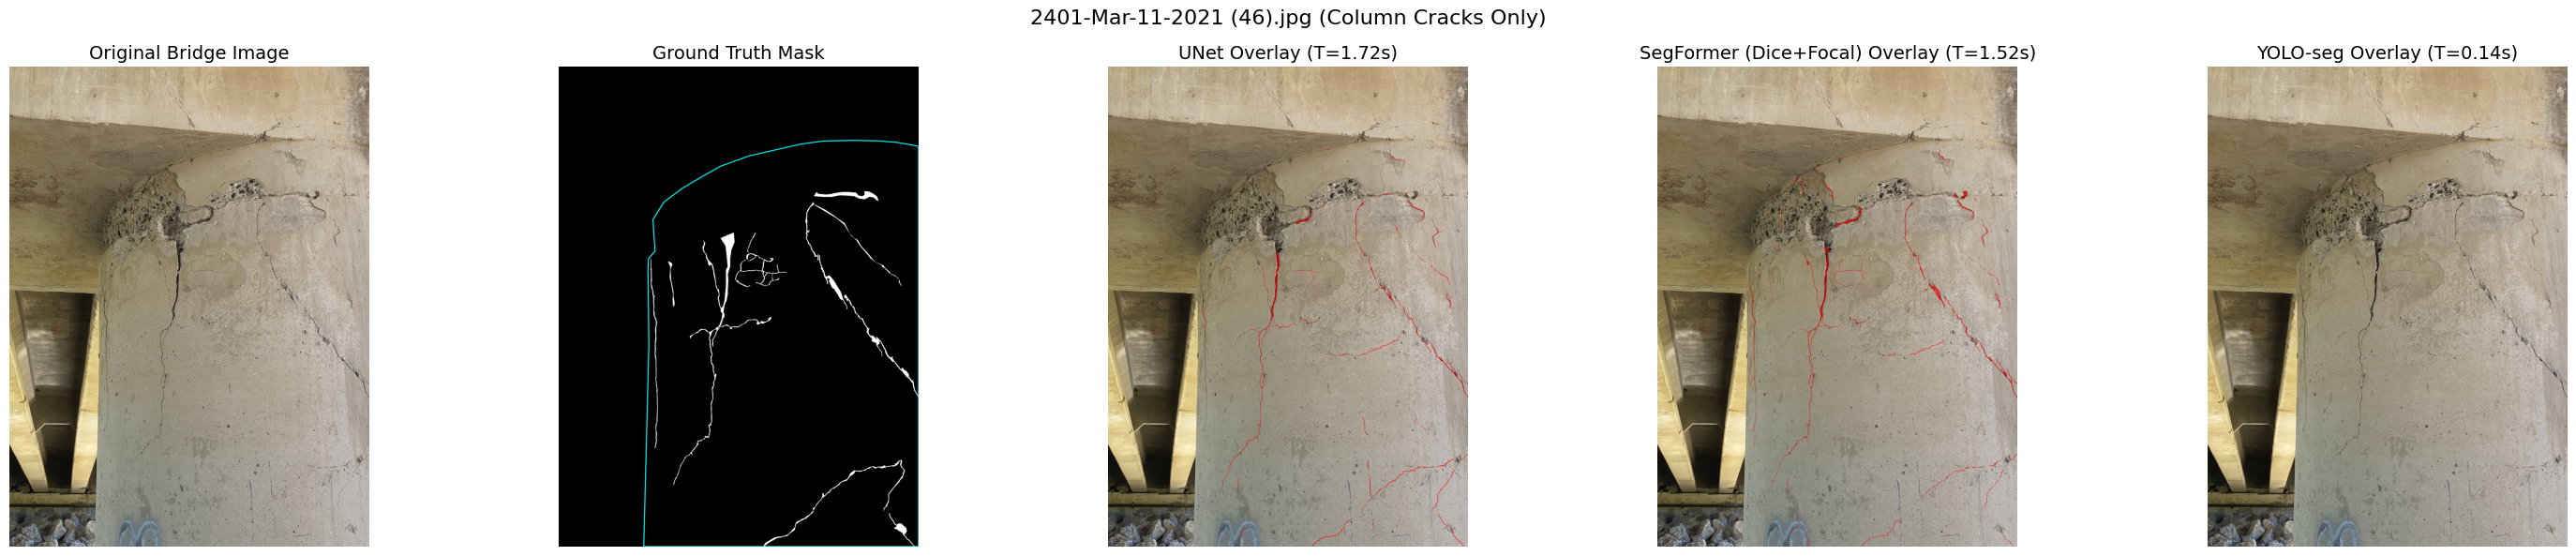

  2401-Mar-11-2021 (46).jpg                                    | UNet: 1.72s | SegFormer (Dice+Focal): 1.52s | YOLO: 0.14s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_2401-Mar-11-2021 (46).png


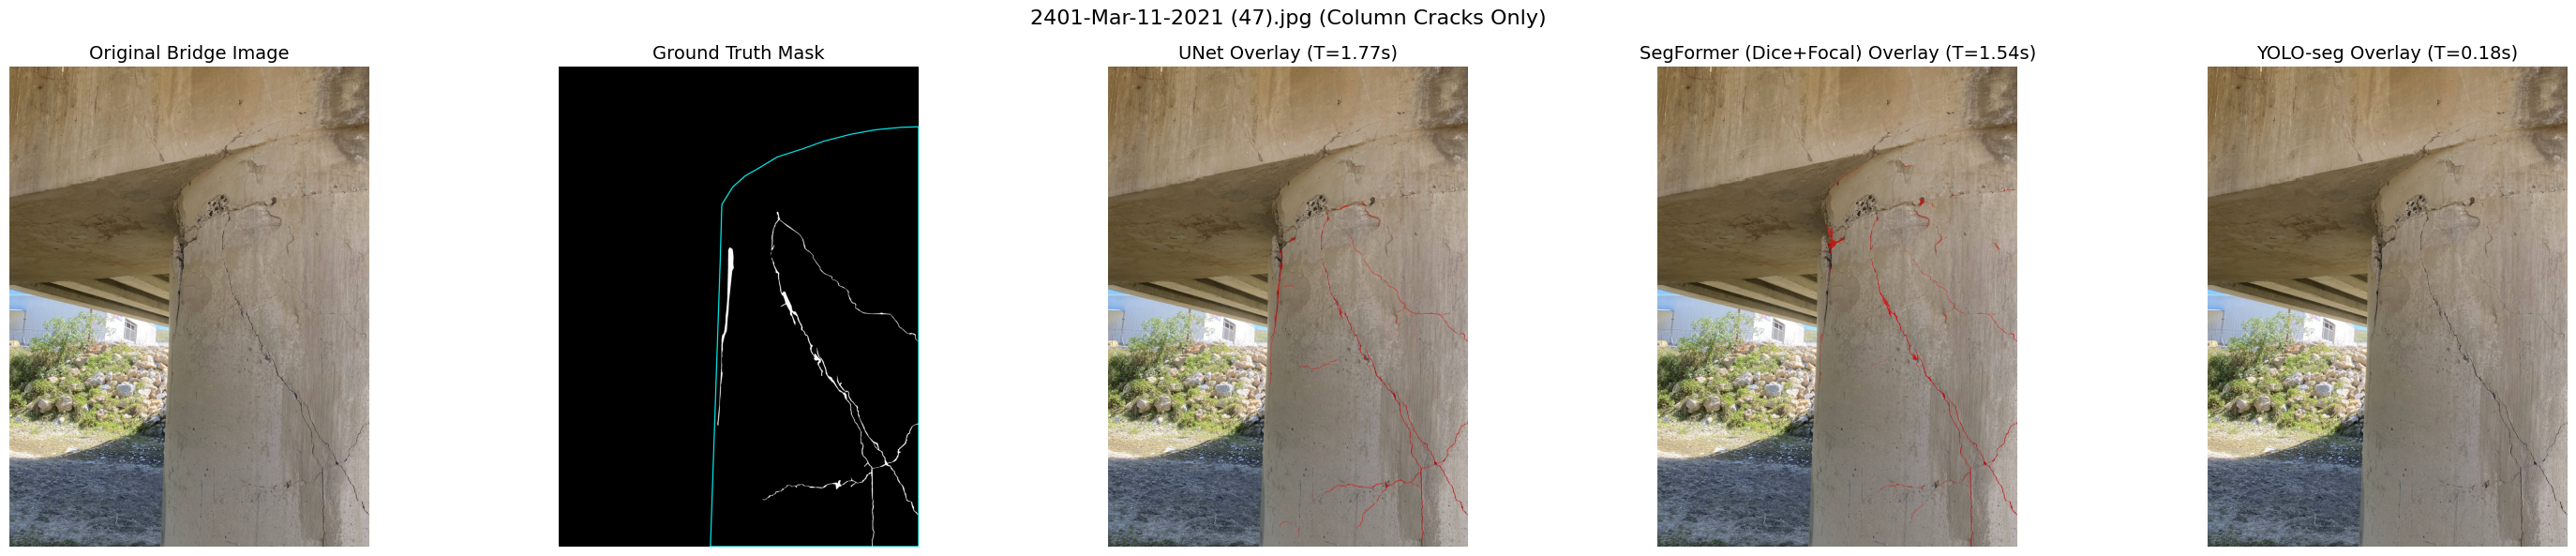

  2401-Mar-11-2021 (47).jpg                                    | UNet: 1.77s | SegFormer (Dice+Focal): 1.54s | YOLO: 0.18s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_2401-Mar-11-2021 (47).png


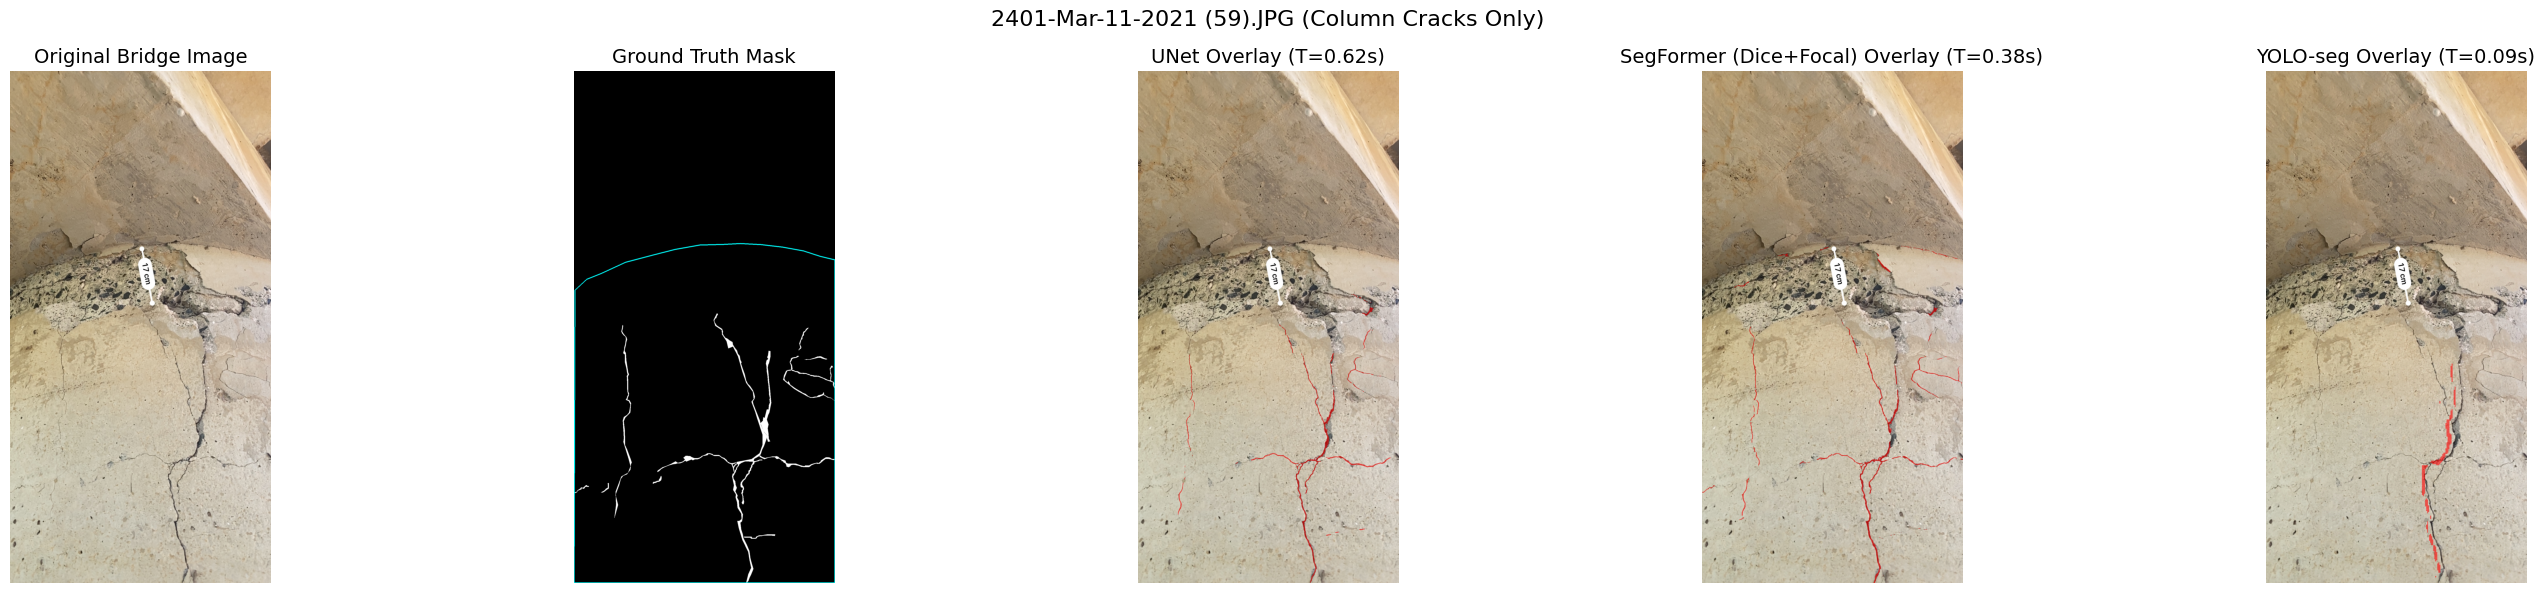

  2401-Mar-11-2021 (59).JPG                                    | UNet: 0.62s | SegFormer (Dice+Focal): 0.38s | YOLO: 0.09s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_2401-Mar-11-2021 (59).png


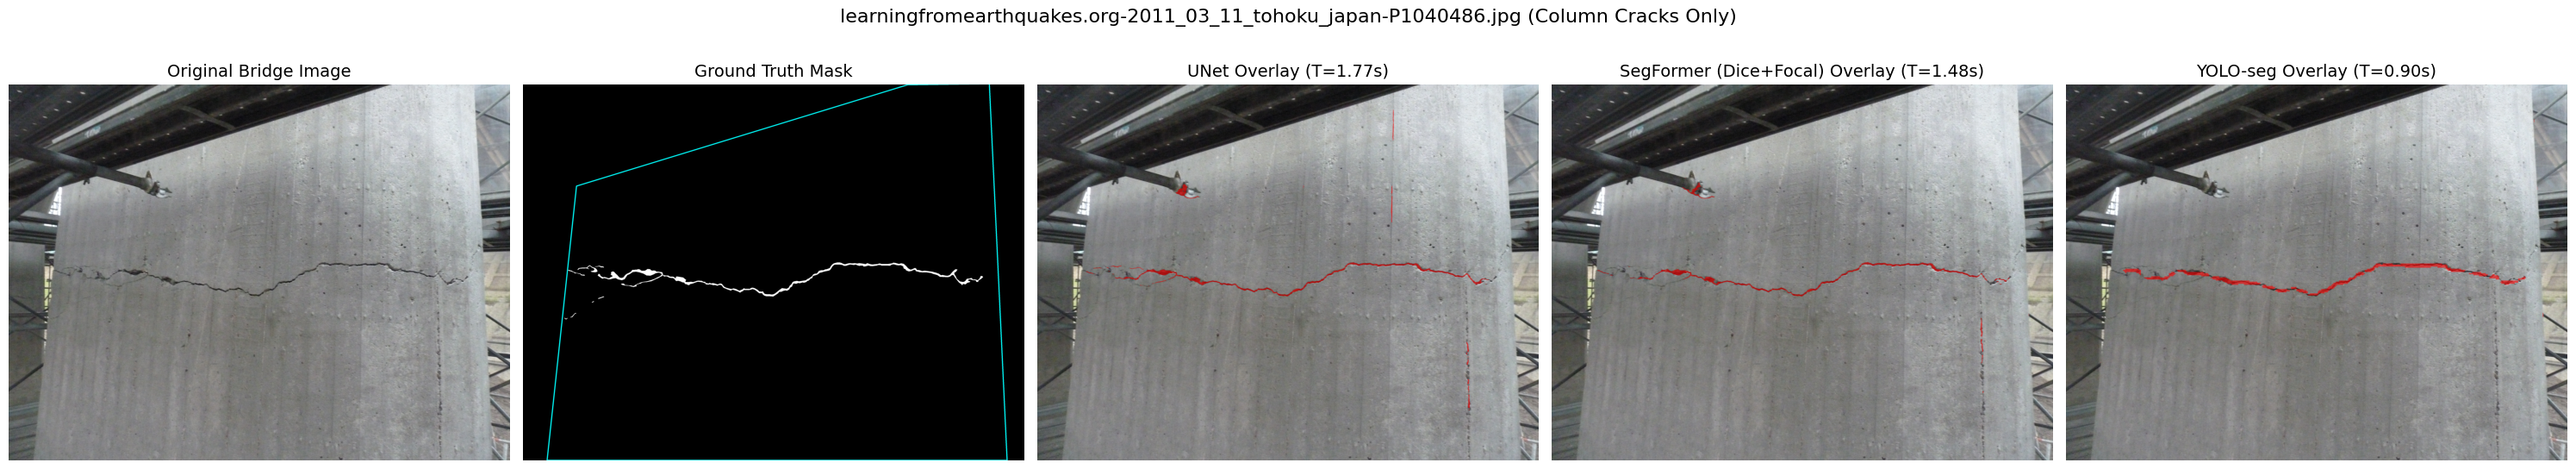

  learningfromearthquakes.org-2011_03_11_tohoku_japan-P1040486.jpg | UNet: 1.77s | SegFormer (Dice+Focal): 1.48s | YOLO: 0.90s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_learningfromearthquakes.org-2011_03_11_tohoku_japan-P1040486.png


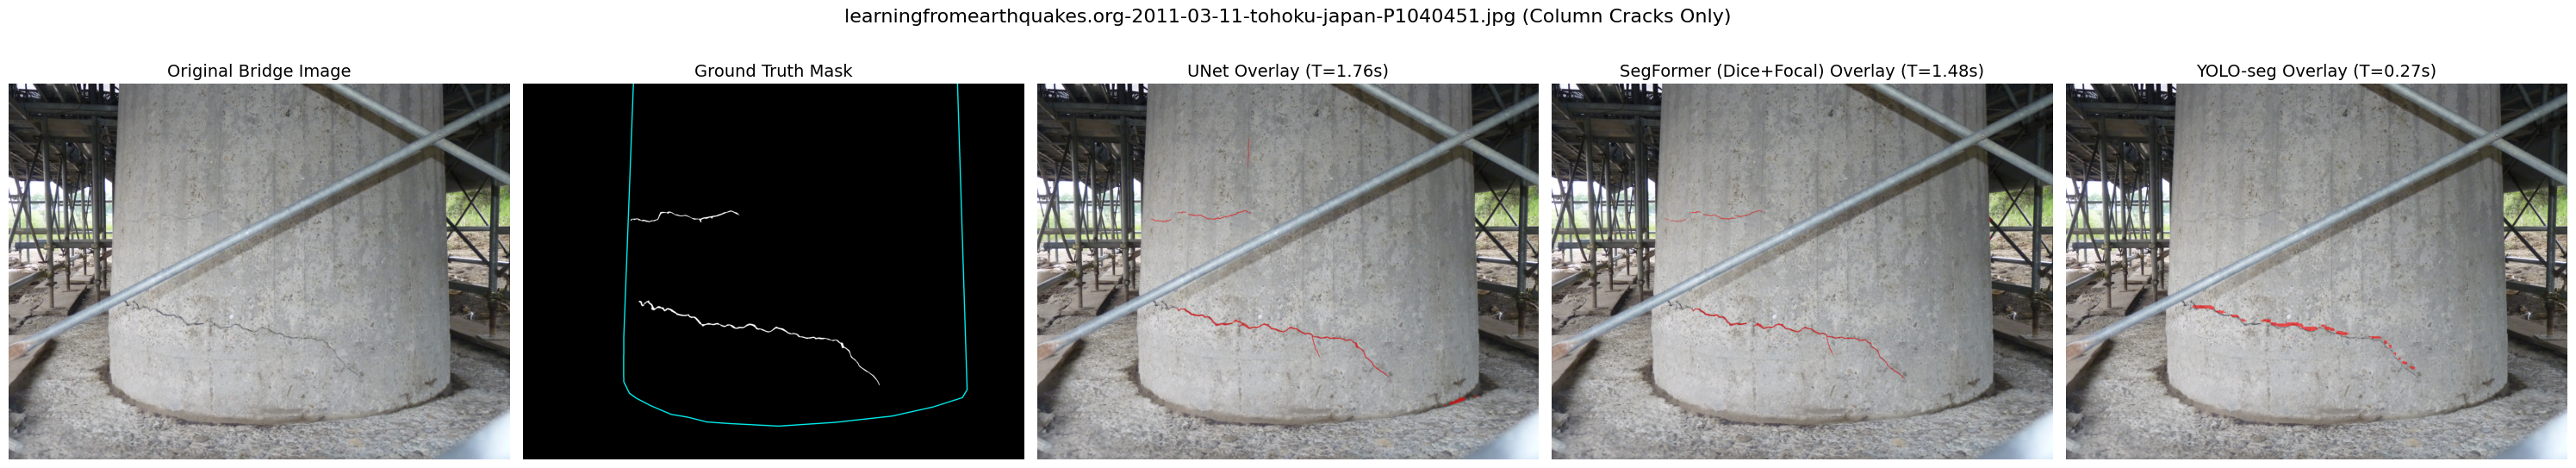

  learningfromearthquakes.org-2011-03-11-tohoku-japan-P1040451.jpg | UNet: 1.76s | SegFormer (Dice+Focal): 1.48s | YOLO: 0.27s
    Saved figure to: C:\Users\abinashm\OneDrive - University of Nevada, Reno\phd research\paper submission\crack-segmentation\crack-seg\experimenting\output\overlay_column_learningfromearthquakes.org-2011-03-11-tohoku-japan-P1040451.png


In [6]:
# ==============================================================================
# Model Overlay Visualization on Real Bridge Samples (Column Restricted)
# Shows: Original Image | Ground Truth Mask | UNet Overlay | SegFormer (Dice+Focal) Overlay | YOLO-seg Overlay
# ==============================================================================
import time
from pathlib import Path
import matplotlib.pyplot as plt

# 1. Select comparison models from loaded_models
models_to_visualize = {
    "UNet": loaded_models.get("UNet (4 Datasets)", (None, None))[1]
            or loaded_models.get("UNet (NCCD-PF)", (None, None))[1],
    "SegFormer (Dice+Focal)": loaded_models.get("SegFormer (Dice+Focal)", (None, None))[1]
                             or loaded_models.get("SegFormer (4 Datasets)", (None, None))[1],
    "YOLO-seg": loaded_models.get("YOLO-seg (4 Datasets)", (None, None))[1],
}

# Validate selected models
for model_name, model_obj in models_to_visualize.items():
    if model_obj is None:
        raise ValueError(f"Required model '{model_name}' was not found in loaded_models.")

# 2. Batched GPU Patch Inference Configuration
PATCH_BATCH_SIZE = 16
USE_AMP = True
PATCH_SIZE = 448
STRIDE = 224
YOLO_CONF = YOLO_CONFIDENCE

# GPU Warmup: run a dummy tensor through PyTorch models to eliminate one-time cuDNN compilation overhead
pytorch_models = [m for m in models_to_visualize.values() if isinstance(m, torch.nn.Module)]
warmup_gpu(
    pytorch_models,
    patch_batch_size=PATCH_BATCH_SIZE,
    patch_size=PATCH_SIZE,
    device=config.DEVICE,
    use_amp=USE_AMP,
)

# Output directory for saving comparison overlay figures
OUTPUT_DIR = config.BASE_DIR / "experimenting" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"\nGenerating 5-panel column-restricted overlay visualizations for {len(bridge_samples)} bridge image(s)...\n")

# 3. Iterate through bridge samples and generate side-by-side overlay plots with Ground Truth Mask and Column ROI
overlay_results = []
for image_name, image_path, col_arr, gt_col_crack, _ in bridge_samples:
    save_fig_path = OUTPUT_DIR / f"overlay_column_{Path(image_name).stem}.png"
    result = visualize_model_overlays(
        image=image_path,
        models=models_to_visualize,
        device=config.DEVICE,
        patch_size=PATCH_SIZE,
        stride=STRIDE,
        batch_size=PATCH_BATCH_SIZE,
        use_amp=USE_AMP,
        yolo_conf=YOLO_CONF,
        alpha=0.6,
        suptitle=f"{image_name} (Column Cracks Only)",
        save_path=save_fig_path,
        show=True,
        roi_mask=col_arr,
        roi_color=(0, 255, 255),  # Cyan contour highlighting column boundary
        ground_truth_mask=gt_col_crack,
        gt_title="Ground Truth Mask",
    )
    t_unet = result["timings"].get("UNet", 0.0)
    t_seg = result["timings"].get("SegFormer (Dice+Focal)", 0.0)
    t_yolo = result["timings"].get("YOLO-seg", 0.0)
    print(f"  {image_name:<60} | UNet: {t_unet:.2f}s | SegFormer (Dice+Focal): {t_seg:.2f}s | YOLO: {t_yolo:.2f}s")
    print(f"    Saved figure to: {save_fig_path}")
    overlay_results.append(result)
